<a href="https://colab.research.google.com/github/felexkuria/Data-Analysyis-using-Python/blob/master/Analysis_Ecommerce.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

```markdown
# Jumia Warehouse Operations & Profitability Pipeline (Reusable)

This pipeline consolidates all analysis steps into clean, modular Python functions.
To reuse this notebook with new data, simply update the file paths and parameters in the configuration cell below and run the entire script.
```

In [ ]:
# =====================================================================
# 1. CONFIGURATION & FILE PATHS
# =====================================================================
DELIVERED_FILE = "/content/orders_export-de787de0-c5e6-44b6-90c6-ef0a0e4cbfb8.csv"
SHIPPED_FILE = "/content/orders_export-f5f5ebce-9f97-43dc-8414-fcd6f7cac554.csv"
NOT_SHIPPED_FILE = "/content/orders_export-13588a1f-fa47-4cad-aa09-fd8f7ab84e1a.csv"
CONSIGNMENT_FILE = "/content/consignment_export_20261112_053027.xlsx"

# Parameters
TARGET_SKU = "SHDB001"
UNIT_COGS = 1800.0
COMMISSION_RATE = 0.12
EXPRESS_SHIPPING_FEE = 70.0
CURRENT_CASH = 66000.0
RESTOCK_TARGET_QTY = 60

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

# Setup plot styles
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

# =====================================================================
# 2. DATA LOADING & CLEANING
# =====================================================================
def load_and_prep_data():
    print("[1/5] Loading and cleaning datasets...")
    # Load main sales data
    df_delivered = pd.read_csv(DELIVERED_FILE)
    df_shipped = pd.read_csv(SHIPPED_FILE)
    df_not_shipped = pd.read_csv(NOT_SHIPPED_FILE)

    # Parse datetime columns
    for df in [df_delivered, df_shipped, df_not_shipped]:
        for col in ['Created At', 'Updated At', 'Shipped Date']:
            if col in df.columns:
                df[col] = pd.to_datetime(df[col])

    # Clean prices
    df_delivered['Clean_Price'] = pd.to_numeric(
        df_delivered['Unit Price'].astype(str).str.replace(' KES', '').str.replace(',', ''),
        errors='coerce'
    )

    # Load consignment data
    df_consignment = pd.read_excel(CONSIGNMENT_FILE)
    df_consignment['CreatedDate'] = pd.to_datetime(df_consignment['CreatedDate'])
    df_consignment['QuantityReceived'] = df_consignment['QuantityReceived'].fillna(0).astype(int)
    df_consignment['QuantitySubmitted'] = df_consignment['QuantitySubmitted'].fillna(0).astype(int)
    df_consignment['Discrepancy'] = df_consignment['QuantitySubmitted'] - df_consignment['QuantityReceived']

    print("-> All datasets loaded and synchronized successfully.\n")
    return df_delivered, df_shipped, df_not_shipped, df_consignment

delivered_df, shipped_df, not_shipped_df, consignment_df = load_and_prep_data()

[1/5] Loading and cleaning datasets...
-> All datasets loaded and synchronized successfully.



/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


[2/5] Running Demand Volatility & Forecast for SKU: SHDB001
  - Mean Monthly Sales Volume: 53.5 units
  - Monthly Demand Volatility (CoV): 40.53%
  - Predicted Sales (Next 30 Days): 65 units (based on recent 2.17/day run-rate)



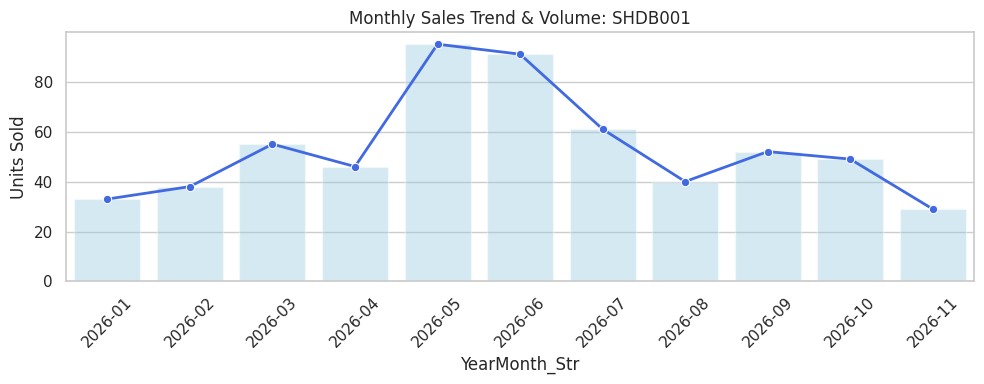

In [ ]:
# =====================================================================
# 3. DEMAND ANALYSIS & FORECASTING
# =====================================================================
def run_demand_analysis(df_delivered, sku):
    print(f"[2/5] Running Demand Volatility & Forecast for SKU: {sku}")
    sku_sales = df_delivered[df_delivered["Seller Sku"] == sku].copy()

    if sku_sales.empty:
        print(f"No sales record found for SKU {sku}.")
        return

    # Monthly sales volume and Coefficient of Variation
    sku_sales['YearMonth'] = sku_sales['Created At'].dt.to_period('M')
    monthly_sales = sku_sales.groupby('YearMonth').size().reset_index(name='Units Sold')

    mean_sales = monthly_sales['Units Sold'].mean()
    std_sales = monthly_sales['Units Sold'].std()
    cov = std_sales / mean_sales if mean_sales != 0 else 0

    # Forecasting based on recent 30-day run-rate
    recent_30d = sku_sales[sku_sales['Created At'] >= (sku_sales['Created At'].max() - pd.Timedelta(30, 'D'))]
    daily_run_rate = len(recent_30d) / 30.0
    predicted_30_days = round(daily_run_rate * 30)

    print(f"  - Mean Monthly Sales Volume: {mean_sales:.1f} units")
    print(f"  - Monthly Demand Volatility (CoV): {cov:.2%}")
    print(f"  - Predicted Sales (Next 30 Days): {predicted_30_days} units (based on recent {daily_run_rate:.2f}/day run-rate)\n")

    # Plot Monthly Trend
    monthly_sales_plot = monthly_sales.copy()
    monthly_sales_plot['YearMonth_Str'] = monthly_sales_plot['YearMonth'].astype(str)
    plt.figure(figsize=(10, 4))
    sns.lineplot(data=monthly_sales_plot, x='YearMonth_Str', y='Units Sold', marker='o', color='royalblue', linewidth=2)
    sns.barplot(data=monthly_sales_plot, x='YearMonth_Str', y='Units Sold', color='skyblue', alpha=0.4)
    plt.title(f'Monthly Sales Trend & Volume: {sku}')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

run_demand_analysis(delivered_df, TARGET_SKU)

In [ ]:
# =====================================================================
# 4. CONSIGNMENT DISCREPANCY AUDIT
# =====================================================================
def audit_consignments(df_consignment, sku):
    print(f"[3/5] Auditing Consignment Warehouse Submissions for SKU: {sku}")
    sku_pos = df_consignment[df_consignment['SellerSKU'] == sku].copy()

    total_sub = sku_pos['QuantitySubmitted'].sum()
    total_rec = sku_pos['QuantityReceived'].sum()
    total_disc = sku_pos['Discrepancy'].sum()

    print(f"  - Total Units Dropped-off / Submitted: {total_sub} units")
    print(f"  - Total Units Marked Received: {total_rec} units")
    print(f"  - Total Unreconciled Shortfall: {total_disc} units")

    discrepant_orders = sku_pos[sku_pos['Discrepancy'] > 0][
        ['ConsignmentOrderNumber', 'CreatedDate', 'QuantitySubmitted', 'QuantityReceived', 'Discrepancy', 'Status']
    ]
    if not discrepant_orders.empty:
        print("\n  -> Top Discrepant Deliveries needing Jumia Support Ticket Intervention:")
        display(discrepant_orders.head(5))
    print("\n")

audit_consignments(consignment_df, TARGET_SKU)

[3/5] Auditing Consignment Warehouse Submissions for SKU: SHDB001
  - Total Units Dropped-off / Submitted: 946 units
  - Total Units Marked Received: 729 units
  - Total Unreconciled Shortfall: 217 units

  -> Top Discrepant Deliveries needing Jumia Support Ticket Intervention:


,ConsignmentOrderNumber,CreatedDate,QuantitySubmitted,QuantityReceived,Discrepancy,Status
0,M2646HL167VD,2026-11-09 16:56:25.815778+00:00,60,0,60,open
2,M26405SLPJSZ,2026-10-03 02:19:05.080806+00:00,60,0,60,open
16,M2625N34E5HW,2026-06-20 20:01:00.466774+00:00,60,0,60,open
22,M2620VFOTR9Q,2026-05-17 12:54:22.965765+00:00,4,3,1,received incomplete
28,M26155WEK42G,2026-04-08 13:37:51.078721+00:00,48,18,30,received incomplete


In [ ]:
# =====================================================================
# 5. EXPRESS WAREHOUSE PROFITABILITY REPORT & CAPITAL SUFFICIENCY
# =====================================================================
def run_profitability_audit(df_delivered, sku):
    print(f"[4/5] Evaluating Express Warehouse Profitability Metrics for {sku}...")

    # Filter express sales
    express_sales = df_delivered[
        (df_delivered['Seller Sku'] == sku) &
        (df_delivered['Shipment Type'] == 'Fulfillment by Jumia')
    ].copy()

    # Apply fee structure
    express_sales['Commission'] = -COMMISSION_RATE * express_sales['Clean_Price']
    express_sales['Shipping_Fee'] = -EXPRESS_SHIPPING_FEE
    express_sales['COGS'] = UNIT_COGS
    express_sales['Net_Payout'] = express_sales['Clean_Price'] + express_sales['Commission'] + express_sales['Shipping_Fee']
    express_sales['Net_Profit'] = express_sales['Net_Payout'] - express_sales['COGS']
    express_sales['Margin'] = (express_sales['Net_Profit'] / express_sales['Clean_Price']) * 100

    # Generate indicators
    total_sales = len(express_sales)
    tot_rev = express_sales['Clean_Price'].sum()
    tot_profit = express_sales['Net_Profit'].sum()
    avg_margin = express_sales['Margin'].mean()

    print(f"  - Total Express Delivered Orders: {total_sales} units")
    print(f"  - Total Sales Revenue: {tot_rev:,.2f} KES")
    print(f"  - Total Net Profit: {tot_profit:,.2f} KES")
    print(f"  - Average Operating Profit Margin: {avg_margin:.2f}%")

    # Restocking Capital Sufficiency Audit
    print(f"\n[5/5] Restocking & Capital Sufficiency Analysis")
    total_cost_needed = RESTOCK_TARGET_QTY * UNIT_COGS
    deficit = total_cost_needed - CURRENT_CASH
    affordable_qty = int(CURRENT_CASH // UNIT_COGS)

    print(f"  - Capital required to purchase target of {RESTOCK_TARGET_QTY} units: {total_cost_needed:,.2f} KES")
    print(f"  - Current cash available: {CURRENT_CASH:,.2f} KES")
    if deficit > 0:
        print(f"  - WARNING: Capital Deficit of {deficit:,.2f} KES. You can only afford {affordable_qty} units.")
    else:
        print(f"  - SUCCESS: Capital is sufficient to proceed with restocking {RESTOCK_TARGET_QTY} units.")

run_profitability_audit(delivered_df, TARGET_SKU)

[4/5] Evaluating Express Warehouse Profitability Metrics for SHDB001...
  - Total Express Delivered Orders: 571 units
  - Total Sales Revenue: 1,726,292.25 KES
  - Total Net Profit: 451,367.18 KES
  - Average Operating Profit Margin: 25.60%

[5/5] Restocking & Capital Sufficiency Analysis
  - Capital required to purchase target of 60 units: 108,000.00 KES
  - Current cash available: 66,000.00 KES
  - WARNING: Capital Deficit of 42,000.00 KES. You can only afford 36 units.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib as plot

In [ ]:
delivered=pd.read_csv("/content/orders_export-de787de0-c5e6-44b6-90c6-ef0a0e4cbfb8.csv")
shipped=pd.read_csv("/content/orders_export-f5f5ebce-9f97-43dc-8414-fcd6f7cac554.csv")
not_shipped=pd.read_csv("/content/orders_export-13588a1f-fa47-4cad-aa09-fd8f7ab84e1a.csv")

In [ ]:
# Counts the number of matching rows
sku_count = (delivered["Seller Sku"] == "SHDB001").sum()
na_count=delivered["Seller Sku"].isna().sum()
print(f"Total delivered for SHDB001: {sku_count}")
print(f"Total NA for SHDB001: {na_count}")


Total delivered for SHDB001: 589
Total NA for SHDB001: 0


In [ ]:
# Counts the number of matching rows
sku_count = (shipped["Seller Sku"] == "SHDB001").sum()
print(f"Total shipped for SHDB001: {sku_count}")

Total shipped for SHDB001: 28


In [ ]:
sku_count=(not_shipped["Seller Sku"]=="SHDB001").sum()
print(f"Total shipped for SHDB001: {sku_count}")

Total shipped for SHDB001: 4


In [ ]:
delivered["Seller Sku"] == "SHDB001"

,Seller Sku
0,True
1,True
2,True
3,True
4,True
...,...
1112,False
1113,True
1114,True
1115,False


In [ ]:
delivered


,Seller Sku,Jumia Sku,Product SID,Created At,Updated At,Shipped Date,Order Number,Customer First Name,Customer Last Name,National Registration Number,...,Shipment Provider,Shipment Type,Shipping Provider Type,Tracking Code,Tracking URL,Package Gross Weight,Package Volumetric Weight,Premium,Status,Cancel Reason
0,SHDB001,SI162HA34V031NAFAMZ-228682088,942b52f9-6811-4b24-8d52-84e0a3bff7b2,2026-01-02 13:23:21,2026-01-08 12:38:54,2026-01-02 14:14:30,387125857,willis,malesi,NaN,...,NaN,Fulfillment by Jumia,NaN,JG-MCC-373288365-7000,https://packagetracker-services.jumia.com/#/KE...,NaN,NaN,No,Delivered,NaN
1,SHDB001,SI162HA34V031NAFAMZ-228682088,942b52f9-6811-4b24-8d52-84e0a3bff7b2,2026-01-02 17:37:03,2026-01-07 16:24:58,2026-01-02 17:54:31,398355857,Andrew,Peter,NaN,...,NaN,Fulfillment by Jumia,NaN,JE-FDQ-398355857-3751,https://packagetracker-services.jumia.com/#/KE...,NaN,NaN,No,Delivered,NaN
2,SHDB001,SI162HA34V031NAFAMZ-228682088,942b52f9-6811-4b24-8d52-84e0a3bff7b2,2026-01-03 09:53:18,2026-01-06 16:37:16,2026-01-03 12:24:48,313411857,Luke,Kirongo,NaN,...,NaN,Fulfillment by Jumia,NaN,JE-FHP-313411857-1617,https://packagetracker-services.jumia.com/#/KE...,NaN,NaN,No,Delivered,NaN
3,SHDB001,SI162HA34V031NAFAMZ-228682088,942b52f9-6811-4b24-8d52-84e0a3bff7b2,2026-01-04 07:50:33,2026-01-06 17:41:13,2026-01-04 14:40:37,312884757,Kabucho,Karanja,NaN,...,NaN,Fulfillment by Jumia,NaN,JG-GAF-321171365-4279,https://packagetracker-services.jumia.com/#/KE...,NaN,NaN,No,Delivered,NaN
4,SHDB001,SI162HA34V031NAFAMZ-228682088,942b52f9-6811-4b24-8d52-84e0a3bff7b2,2026-01-06 19:31:21,2026-01-09 18:50:34,2026-01-07 11:38:23,357337757,augustine,nyakiba,NaN,...,NaN,Fulfillment by Jumia,NaN,NaN,https://packagetracker-services.jumia.com/#/KE...,NaN,NaN,No,Delivered,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1112,DST001,GE840EA659E3UNAFAMZ-461365251,b530b216-739e-496e-b6e3-d5a844266721,2026-11-09 08:45:26,2026-11-10 12:56:22,2026-11-09 12:51:16,391264555,Suleiman,Asman,NaN,...,NaN,Fulfillment by Jumia,NaN,JE-IAB-391264555-6879,https://packagetracker-services.jumia.com/#/KE...,NaN,NaN,No,Delivered,NaN
1113,SHDB001,SI162HA34V031NAFAMZ-228682088,942b52f9-6811-4b24-8d52-84e0a3bff7b2,2026-11-09 10:44:19,2026-11-10 13:25:55,2026-11-09 12:53:45,325574555,Nancy,Abuga,NaN,...,NaN,Fulfillment by Jumia,NaN,JE-ADF-325574555-2567,https://packagetracker-services.jumia.com/#/KE...,NaN,NaN,No,Delivered,NaN
1114,SHDB001,SI162HA34V031NAFAMZ-228682088,942b52f9-6811-4b24-8d52-84e0a3bff7b2,2026-11-09 20:45:28,2026-11-11 12:43:13,2026-11-10 02:12:45,322436555,Freddy,Lumbs,NaN,...,NaN,Fulfillment by Jumia,NaN,JE-ADF-322436555-5250,https://packagetracker-services.jumia.com/#/KE...,NaN,NaN,No,Delivered,NaN
1115,DST001,GE840EA659E3UNAFAMZ-461365251,b530b216-739e-496e-b6e3-d5a844266721,2026-11-09 22:10:21,2026-11-11 16:45:48,2026-11-10 00:31:47,349729555,Simon,Jura,NaN,...,NaN,Fulfillment by Jumia,NaN,JE-ACB-349729555-7005,https://packagetracker-services.jumia.com/#/KE...,NaN,NaN,No,Delivered,NaN


In [ ]:
df=delivered.tail()

In [ ]:
df

,Seller Sku,Jumia Sku,Product SID,Created At,Updated At,Shipped Date,Order Number,Customer First Name,Customer Last Name,National Registration Number,...,Shipment Provider,Shipment Type,Shipping Provider Type,Tracking Code,Tracking URL,Package Gross Weight,Package Volumetric Weight,Premium,Status,Cancel Reason
1112,DST001,GE840EA659E3UNAFAMZ-461365251,b530b216-739e-496e-b6e3-d5a844266721,2026-11-09 08:45:26,2026-11-10 12:56:22,2026-11-09 12:51:16,391264555,Suleiman,Asman,NaN,...,NaN,Fulfillment by Jumia,NaN,JE-IAB-391264555-6879,https://packagetracker-services.jumia.com/#/KE...,NaN,NaN,No,Delivered,NaN
1113,SHDB001,SI162HA34V031NAFAMZ-228682088,942b52f9-6811-4b24-8d52-84e0a3bff7b2,2026-11-09 10:44:19,2026-11-10 13:25:55,2026-11-09 12:53:45,325574555,Nancy,Abuga,NaN,...,NaN,Fulfillment by Jumia,NaN,JE-ADF-325574555-2567,https://packagetracker-services.jumia.com/#/KE...,NaN,NaN,No,Delivered,NaN
1114,SHDB001,SI162HA34V031NAFAMZ-228682088,942b52f9-6811-4b24-8d52-84e0a3bff7b2,2026-11-09 20:45:28,2026-11-11 12:43:13,2026-11-10 02:12:45,322436555,Freddy,Lumbs,NaN,...,NaN,Fulfillment by Jumia,NaN,JE-ADF-322436555-5250,https://packagetracker-services.jumia.com/#/KE...,NaN,NaN,No,Delivered,NaN
1115,DST001,GE840EA659E3UNAFAMZ-461365251,b530b216-739e-496e-b6e3-d5a844266721,2026-11-09 22:10:21,2026-11-11 16:45:48,2026-11-10 00:31:47,349729555,Simon,Jura,NaN,...,NaN,Fulfillment by Jumia,NaN,JE-ACB-349729555-7005,https://packagetracker-services.jumia.com/#/KE...,NaN,NaN,No,Delivered,NaN
1116,SHDB001,SI162HA34V031NAFAMZ-228682088,942b52f9-6811-4b24-8d52-84e0a3bff7b2,2026-11-11 14:25:18,2026-11-11 17:46:20,2026-11-11 14:51:14,316954155,Ann,wanja,NaN,...,NaN,Fulfillment by Jumia,express,JE-IAC-316954155-9829,https://packagetracker-services.jumia.com/#/KE...,NaN,NaN,No,Delivered,NaN


In [ ]:
new_date=pd.to_datetime(df["Updated At"])

In [ ]:
new_date

758   2026-11-03 09:15:41
761   2026-10-31 14:43:00
762   2026-11-03 16:51:39
764   2026-10-31 19:43:12
765   2026-11-04 09:07:08
Name: Updated At, dtype: datetime64[us]

In [ ]:
# 1. Convert the 'Updated At' column from String (text) to Datetime
delivered["Updated At"] = pd.to_datetime(delivered["Updated At"])
delivered["Created At"] = pd.to_datetime(delivered["Created At"])
delivered["Shipped Date"] = pd.to_datetime(delivered["Shipped Date"])
thirty_days_ago=pd.Timestamp.now()-pd.Timedelta(30,"D")
sku_filter=delivered["Seller Sku"]=="SHDB001"
date_condition = delivered["Updated At"] >= thirty_days_ago

In [ ]:
df=delivered[sku_filter &date_condition]

In [ ]:
sku_count = (df["Seller Sku"]=="SHDB001").sum()
print(sku_count)

72


In [ ]:
# Counts the number of matching rows
sku_count = (df["Seller Sku"] == "SHDB001").sum()
print(f"Total delivered for  in last 30 days SHDB001: {sku_count}")


Total delivered for  in last 30 days SHDB001: 72


In [ ]:
# Counts the number of matching rows
sku_count = (shipped["Seller Sku"] == "SHDB001").sum()
print(f"Total shipped for SHDB001: {sku_count}")

Total shipped for SHDB001: 28


In [ ]:
sku_count=(not_shipped["Seller Sku"]=="SHDB001").sum()
print(f"Total shipped for SHDB001: {sku_count}")

Total shipped for SHDB001: 4


In [ ]:
df["Order Number"]

,Order Number
970,381889775
971,318319775
975,335193775
976,343953775
980,399482575
...,...
1109,379781755
1110,334751755
1113,325574555
1114,322436555


### 1. Calculate Monthly Coefficient of Variation (CoV) for SKU `SHDB001`

In [ ]:
# Filter for SHDB001 in delivered sales
shdb_sales = delivered[delivered["Seller Sku"] == "SHDB001"].copy()

# Create a Year-Month column for grouping
shdb_sales['YearMonth'] = shdb_sales['Created At'].dt.to_period('M')

# Group by month and count the number of units sold
monthly_sales = shdb_sales.groupby('YearMonth').size().reset_index(name='Units Sold')
print("--- Monthly Sales ---")
display(monthly_sales)

# Calculate mean, standard deviation, and CoV (Coefficient of Variation = std / mean)
mean_sales = monthly_sales['Units Sold'].mean()
std_sales = monthly_sales['Units Sold'].std()
cov = std_sales / mean_sales if mean_sales != 0 else 0

print(f"\nAverage Monthly Sales: {mean_sales:.2f}")
print(f"Standard Deviation of Monthly Sales: {std_sales:.2f}")
print(f"Coefficient of Variation (CoV): {cov:.4f}")

--- Monthly Sales ---


,YearMonth,Units Sold
0,2026-01,33
1,2026-02,38
2,2026-03,55
3,2026-04,46
4,2026-05,95
5,2026-06,91
6,2026-07,61
7,2026-08,40
8,2026-09,52
9,2026-10,49



Average Monthly Sales: 53.55
Standard Deviation of Monthly Sales: 21.70
Coefficient of Variation (CoV): 0.4053


### 2. Predict Sales for the Next 30 Days

In [ ]:
# Calculate daily sales trend to forecast the next 30 days
daily_sales = shdb_sales.groupby(shdb_sales['Created At'].dt.date).size().reset_index(name='Units Sold')

# Let's project based on the average daily run rate from the most active/recent period
# We will use the average daily sales rate of the last 30 days of data present
recent_sales = shdb_sales[shdb_sales['Created At'] >= (shdb_sales['Created At'].max() - pd.Timedelta(30, 'D'))]
daily_rate_recent = len(recent_sales) / 30.0

# Alternatively, the overall daily average rate across the entire history
total_days = (shdb_sales['Created At'].max() - shdb_sales['Created At'].min()).days
daily_rate_overall = len(shdb_sales) / total_days if total_days > 0 else 0

predicted_30_days_recent = round(daily_rate_recent * 30)
predicted_30_days_overall = round(daily_rate_overall * 30)

print(f"--- Blender (SHDB001) Sales Forecast for Next 30 Days ---")
print(f"Based on recent 30-day run rate ({daily_rate_recent:.2f} units/day): {predicted_30_days_recent} units")
print(f"Based on overall historical run rate ({daily_rate_overall:.2f} units/day): {predicted_30_days_overall} units")

--- Blender (SHDB001) Sales Forecast for Next 30 Days ---
Based on recent 30-day run rate (2.17 units/day): 65 units
Based on overall historical run rate (1.88 units/day): 56 units


In [ ]:
POs_df=pd.read_excel("/content/consignment_export_20261112_053027.xlsx")

/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


In [ ]:
POs_df

,ConsignmentOrderNumber,Country,SellerName,user,ProductName,SellerSKU,JumiaSKU,Currency,UnitPrice,QuantitySubmitted,QuantityReceived,CreatedDate,Status,ShipmentStatus,TrackingNumber,3PLName,DeliveryAgentMobileNumber,ActualDepartureTime,EstimatedArrivalTime
0,M2646HL167VD,Kenya,Multi-touch Enterprise Kenya,jamleckirungu2@gmail.com,2 in 1 Heavy duty Commercial Blender,SHDB001,SI162HA34V031NAFAMZ-228682088,KES,3399.00,60,0,2026-11-09T16:56:25.815778Z,open,Not Shipped,NaN,NaN,NaN,NaN,NaN
1,M2642NV0XV7J,Kenya,Multi-touch Enterprise Kenya,michael.kahindi@jumia.com,RE-PT08 TWS Wireless Earbuds Bluetooth 5.3,RE-PT-08,RE644EA6ALG7CNAFAMZ-469628366,KES,999.00,50,50,2026-10-12T07:09:04.871146Z,received,Not Shipped,NaN,NaN,NaN,NaN,NaN
2,M26405SLPJSZ,Kenya,Multi-touch Enterprise Kenya,jamleckirungu2@gmail.com,2 in 1 Heavy duty Commercial Blender,SHDB001,SI162HA34V031NAFAMZ-228682088,KES,3399.00,60,0,2026-10-03T02:19:05.080806Z,open,Not Shipped,NaN,NaN,NaN,NaN,NaN
3,M2640229CJP4,Kenya,Multi-touch Enterprise Kenya,jamleckirungu2@gmail.com,Period Cramp Relief Massager & Heating Pad for...,PMB001,GE840ST658VPCNAFAMZ-466868248,KES,1129.00,8,8,2026-09-28T12:56:53.310612Z,received,Not Shipped,NaN,NaN,NaN,NaN,NaN
4,M2640229CJP4,Kenya,Multi-touch Enterprise Kenya,jamleckirungu2@gmail.com,Multi-Function USB Data Cable Set – 60W Fast C...,DST001,GE840EA659E3UNAFAMZ-461365251,KES,599.00,50,50,2026-09-28T12:56:53.307045Z,received,Not Shipped,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59,M2402RFNY7UK,Kenya,Multi-touch Enterprise Kenya,jamleckirungu2@gmail.com,3.5mm Lapel Lavalier Omnidirectional Micropho...,NaN,GE840EA026HEDNAFAMZ-89550316,KES,1969.92,10,0,2024-01-12T17:42:19.543304Z,cancelled,Not Shipped,NaN,NaN,NaN,NaN,NaN
60,M2402RFNY7UK,Kenya,Multi-touch Enterprise Kenya,jamleckirungu2@gmail.com,"Straight Synthetic Wigs 24""",NaN,GE840ST2IDC56NAFAMZ-210981121,KES,6567.48,2,0,2024-01-12T17:42:19.491660Z,cancelled,Not Shipped,NaN,NaN,NaN,NaN,NaN
61,M2402RFNY7UK,Kenya,Multi-touch Enterprise Kenya,jamleckirungu2@gmail.com,African Explosive Head Soft Wig Caterpillar Wi...,NaN,GE840ST26AI4QNAFAMZ-210040687,KES,7881.30,1,0,2024-01-12T17:42:19.432412Z,cancelled,Not Shipped,NaN,NaN,NaN,NaN,NaN
62,M2402RFNY7UK,Kenya,Multi-touch Enterprise Kenya,jamleckirungu2@gmail.com,Spiral Short-Wave Bob Wig,NaN,GE840ST2NBG6INAFAMZ-210981412,KES,8318.70,3,0,2024-01-12T17:42:19.367096Z,cancelled,Not Shipped,NaN,NaN,NaN,NaN,NaN


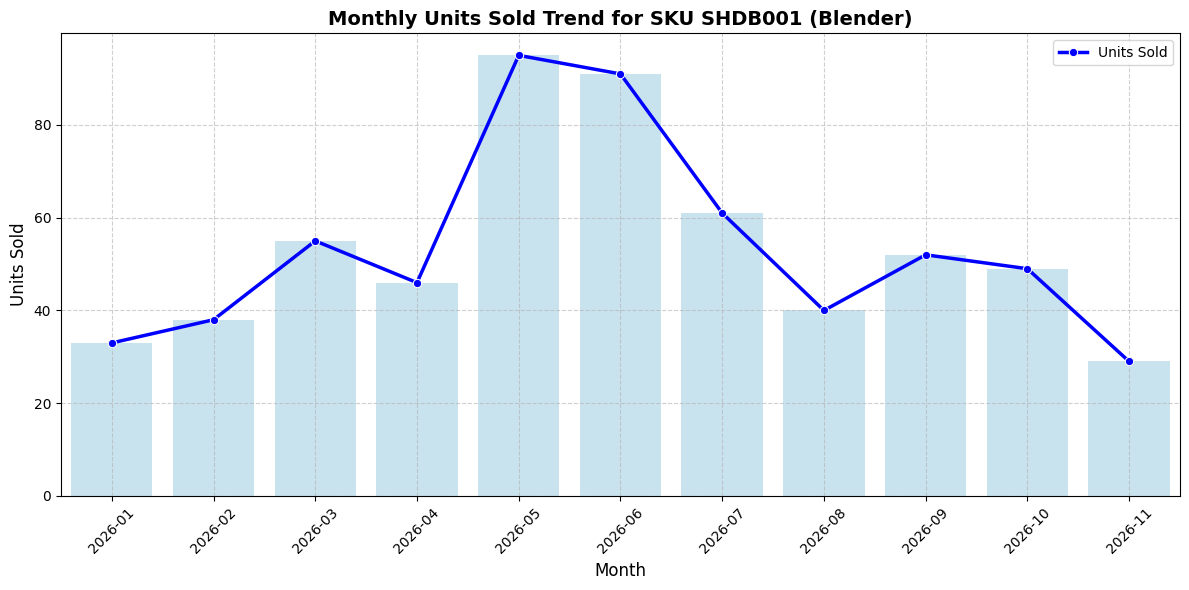

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Convert YearMonth back to string format for plotting purposes
plot_df = monthly_sales.copy()
plot_df['YearMonth_Str'] = plot_df['YearMonth'].astype(str)

# Create the plot
plt.figure(figsize=(12, 6))
sns.lineplot(data=plot_df, x='YearMonth_Str', y='Units Sold', marker='o', color='b', linewidth=2.5, label='Units Sold')
sns.barplot(data=plot_df, x='YearMonth_Str', y='Units Sold', color='skyblue', alpha=0.5)

# Customize chart labels and title
plt.title('Monthly Units Sold Trend for SKU SHDB001 (Blender)', fontsize=14, fontweight='bold')
plt.xlabel('Month', fontsize=12)
plt.ylabel('Units Sold', fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()

# Show the visualization
plt.show()

In [ ]:
# Let's see the column names of POs_df to find the correct status column
print("Columns in POs_df:", POs_df.columns.tolist())

# Filter for SKU 'SHDB001'
sku_pos = POs_df[POs_df['SellerSKU'] == 'SHDB001']
print(f"Total records for SHDB001 in POs_df: {len(sku_pos)}")

# Since status column names might vary, let's look at the unique values of likely status columns
status_cols = [col for col in POs_df.columns if 'status' in col.lower() or 'state' in col.lower()]
for col in status_cols:
    print(f"\nValue counts for column '{col}':")
    print(sku_pos[col].value_counts(dropna=False))

Columns in POs_df: ['ConsignmentOrderNumber', 'Country', 'SellerName', 'user', 'ProductName', 'SellerSKU', 'JumiaSKU', 'Currency', 'UnitPrice', 'QuantitySubmitted', 'QuantityReceived', 'CreatedDate', 'Status', 'ShipmentStatus', 'TrackingNumber', '3PLName', 'DeliveryAgentMobileNumber', 'ActualDepartureTime', 'EstimatedArrivalTime']
Total records for SHDB001 in POs_df: 26

Value counts for column 'Status':
Status
received               19
open                    3
received incomplete     3
cancelled               1
Name: count, dtype: int64

Value counts for column 'ShipmentStatus':
ShipmentStatus
Not Shipped    26
Name: count, dtype: int64


In [ ]:
# Filter for SHDB001 in POs_df
sku_pos = POs_df[POs_df['SellerSKU'] == 'SHDB001']

# Define the statuses that mean 'delivered' in this consignment sheet
delivered_statuses = ['received', 'received incomplete']
delivered_pos = sku_pos[sku_pos['Status'].isin(delivered_statuses)]

# Sum up the quantities
total_records_received = len(delivered_pos)
total_qty_received = delivered_pos['QuantityReceived'].sum()
total_qty_submitted = delivered_pos['QuantitySubmitted'].sum()

print("--- POs_df Delivery Count for SHDB001 ---")
print(f"Total PO records marked as received/received incomplete: {total_records_received}")
print(f"Total quantity submitted: {total_qty_submitted}")
print(f"Total actual quantity received (delivered): {total_qty_received}")

--- POs_df Delivery Count for SHDB001 ---
Total PO records marked as received/received incomplete: 22
Total quantity submitted: 760
Total actual quantity received (delivered): 729


### Consignment Warehouse Discrepancy (Dropped vs Received Items)
Let's calculate the exact discrepancy of SKU `SHDB001` units submitted versus received at the warehouse and plot this trend.

In [ ]:
# Calculate discrepancy
sku_pos = POs_df[POs_df['SellerSKU'] == 'SHDB001'].copy()
sku_pos['CreatedDate'] = pd.to_datetime(sku_pos['CreatedDate'])

# Calculate how many units were 'lost' or not fully received
sku_pos['Discrepancy'] = sku_pos['QuantitySubmitted'] - sku_pos['QuantityReceived']
total_submitted = sku_pos['QuantitySubmitted'].sum()
total_received = sku_pos['QuantityReceived'].sum()
total_discrepancy = sku_pos['Discrepancy'].sum()

print(f"Total SKU SHDB001 Units Submitted: {total_submitted}")
print(f"Total SKU SHDB001 Units Received: {total_received}")
print(f"Total Shortfall / Discrepancy (Dropped off but not received): {total_discrepancy}")

# Display records with discrepancy
discrepant_pos = sku_pos[sku_pos['Discrepancy'] > 0][['ConsignmentOrderNumber', 'CreatedDate', 'QuantitySubmitted', 'QuantityReceived', 'Discrepancy', 'Status']]
display(discrepant_pos)

Total SKU SHDB001 Units Submitted: 946
Total SKU SHDB001 Units Received: 729
Total Shortfall / Discrepancy (Dropped off but not received): 217


,ConsignmentOrderNumber,CreatedDate,QuantitySubmitted,QuantityReceived,Discrepancy,Status
0,M2646HL167VD,2026-11-09 16:56:25.815778+00:00,60,0,60,open
2,M26405SLPJSZ,2026-10-03 02:19:05.080806+00:00,60,0,60,open
16,M2625N34E5HW,2026-06-20 20:01:00.466774+00:00,60,0,60,open
22,M2620VFOTR9Q,2026-05-17 12:54:22.965765+00:00,4,3,1,received incomplete
28,M26155WEK42G,2026-04-08 13:37:51.078721+00:00,48,18,30,received incomplete
53,M2543MGSL4AS,2025-10-26 04:50:22.468599+00:00,6,0,6,cancelled


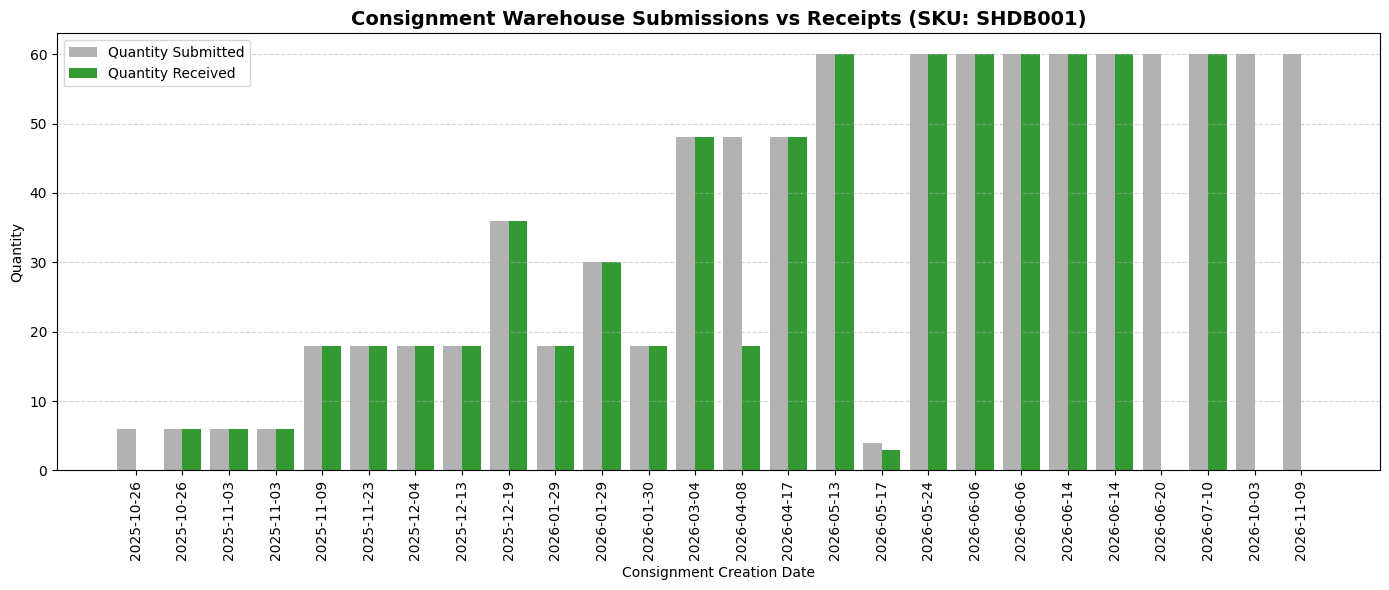

In [ ]:
# Visualize Quantity Submitted vs Received
import matplotlib.pyplot as plt
import seaborn as sns

# Sort by Date for plotting
sku_pos_sorted = sku_pos.sort_values('CreatedDate')
sku_pos_sorted['CreatedDate_Str'] = sku_pos_sorted['CreatedDate'].dt.strftime('%Y-%m-%d')

plt.figure(figsize=(14, 6))
x = range(len(sku_pos_sorted))

plt.bar([i - 0.2 for i in x], sku_pos_sorted['QuantitySubmitted'], width=0.4, label='Quantity Submitted', color='gray', alpha=0.6)
plt.bar([i + 0.2 for i in x], sku_pos_sorted['QuantityReceived'], width=0.4, label='Quantity Received', color='green', alpha=0.8)

plt.xticks(x, sku_pos_sorted['CreatedDate_Str'], rotation=90)
plt.title('Consignment Warehouse Submissions vs Receipts (SKU: SHDB001)', fontsize=14, fontweight='bold')
plt.xlabel('Consignment Creation Date')
plt.ylabel('Quantity')
plt.legend()
plt.grid(True, axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Historical Context: Examining May & June 2026 Sales Peak
Let's analyze the exact day-by-day sales pattern for May and June 2026 to see if there is a concentrated spike indicating promotional campaigns like the Jumia Anniversary.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

# 1. Aggregate historical net profits by Year-Month from the itemized_report
itemized_report['YearMonth'] = itemized_report['Order Date'].dt.to_period('M')
monthly_profits = itemized_report.groupby('YearMonth')['Net Profit (KES)'].sum().reset_index()

# Create a continuous numeric feature representing months elapsed
monthly_profits['MonthIndex'] = np.arange(len(monthly_profits))

# 2. Train a Linear Regression model using scikit-learn
X = monthly_profits[['MonthIndex']]
y = monthly_profits['Net Profit (KES)']

model = LinearRegression()
model.fit(X, y)

# Predict for November (the next sequential month index)
next_month_index = len(monthly_profits)
predicted_nov_profit = model.predict([[next_month_index]])[0]

# Format YearMonth as string for plotting
monthly_profits['YearMonth_Str'] = monthly_profits['YearMonth'].astype(str)

print(f"=== NOVEMBER PROFIT PROJECTION REPORT ===")
print(f"Projected Net Profit for November 2026: {predicted_nov_profit:,.2f} KES")
print(f"Model Coefficients (Slope): {model.coef_[0]:,.2f} KES / month")
print(f"Model Intercept: {model.intercept_:,.2f} KES")


=== NOVEMBER PROFIT PROJECTION REPORT ===
Projected Net Profit for November 2026: 21,555.38 KES
Model Coefficients (Slope): -3,473.35 KES / month
Model Intercept: 59,762.19 KES


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


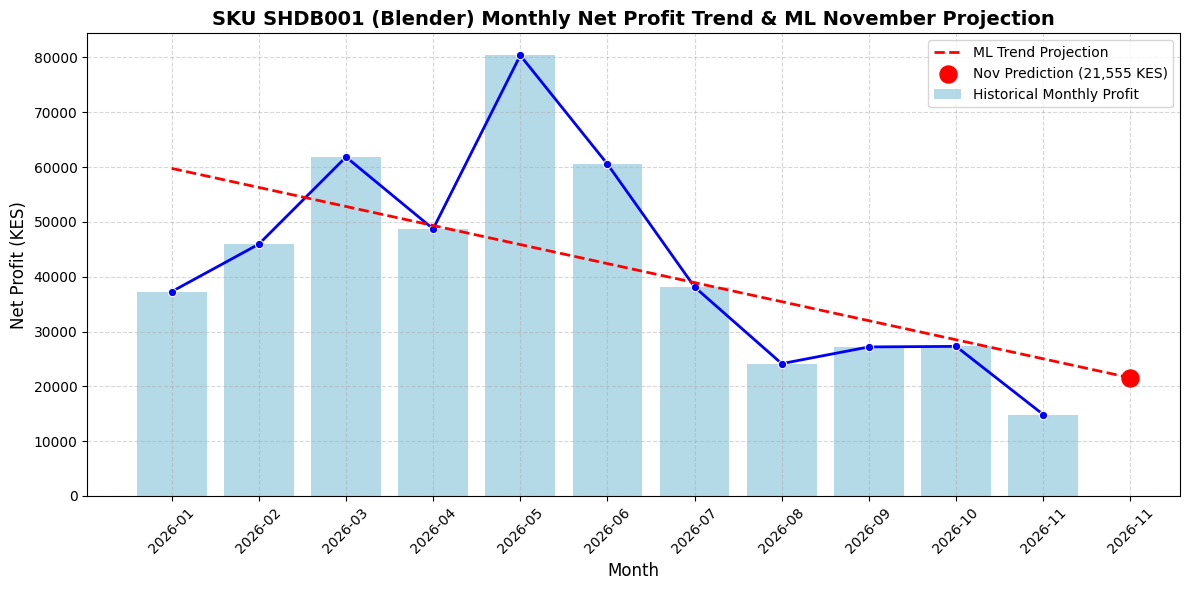

In [ ]:
# 3. Visualize the historical trends and the November machine learning projection
plt.figure(figsize=(12, 6))

# Plot historical monthly profits
sns.barplot(data=monthly_profits, x='YearMonth_Str', y='Net Profit (KES)', color='skyblue', alpha=0.7, label='Historical Monthly Profit')
sns.lineplot(data=monthly_profits, x='YearMonth_Str', y='Net Profit (KES)', marker='o', color='blue', linewidth=2)

# Plot the predicted point for November
all_months = list(monthly_profits['YearMonth_Str']) + ['2026-11']
x_indices = range(len(all_months))

# Draw trend line extending to November
trend_line_y = model.predict(np.arange(len(all_months)).reshape(-1, 1))
plt.plot(x_indices, trend_line_y, color='red', linestyle='--', linewidth=2, label='ML Trend Projection')
plt.scatter(len(all_months) - 1, predicted_nov_profit, color='red', s=150, zorder=5, label=f'Nov Prediction ({predicted_nov_profit:,.0f} KES)')

plt.title('SKU SHDB001 (Blender) Monthly Net Profit Trend & ML November Projection', fontsize=14, fontweight='bold')
plt.xlabel('Month', fontsize=12)
plt.ylabel('Net Profit (KES)', fontsize=12)
plt.xticks(ticks=range(len(all_months)), labels=all_months, rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Calculate total net profit across the full itemized_report dataset
total_itemized_net_profit = itemized_report['Net Profit (KES)'].sum()
print(f"Total Net Profit (Itemized sum): {total_itemized_net_profit:,.2f} KES")


Total Net Profit (Itemized sum): 466,350.06 KES


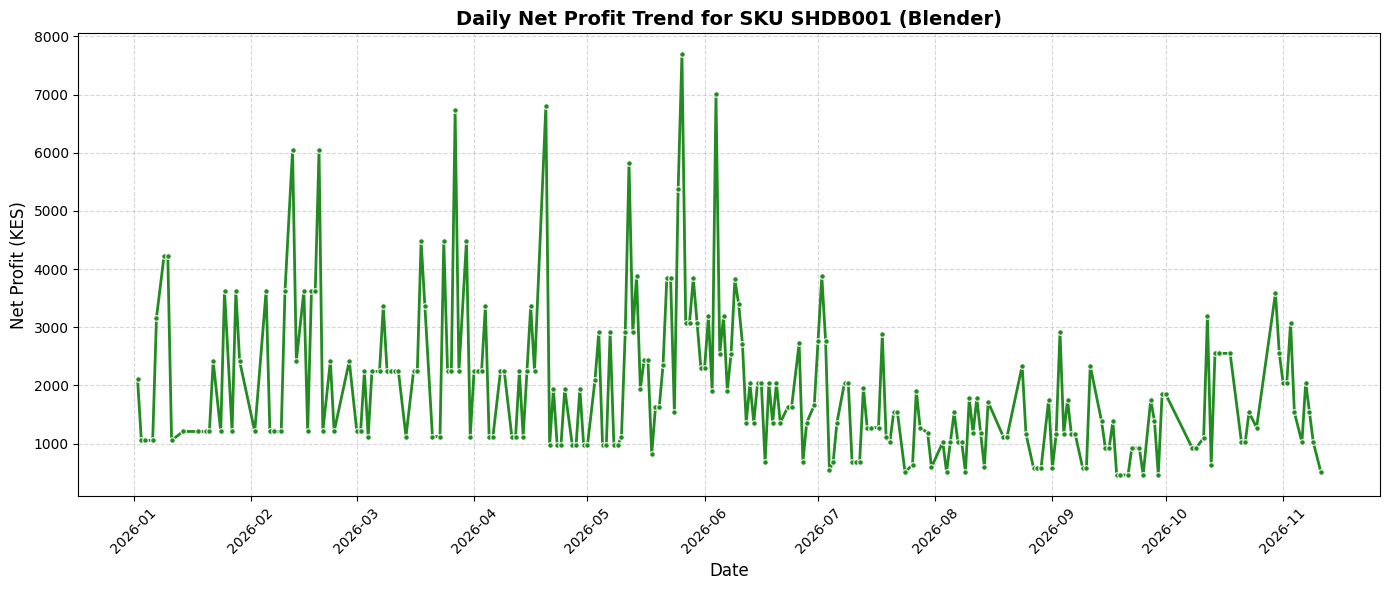

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Group the itemized transactions by date and sum the profits
# First, ensure 'Order Date' is in datetime format
itemized_report['Order Date'] = pd.to_datetime(itemized_report['Order Date'])
daily_profits = itemized_report.groupby(itemized_report['Order Date'].dt.date)['Net Profit (KES)'].sum().reset_index()

# Create the time-series plot
plt.figure(figsize=(14, 6))
sns.lineplot(data=daily_profits, x='Order Date', y='Net Profit (KES)', color='forestgreen', linewidth=2, marker='o', markersize=4)

plt.title('Daily Net Profit Trend for SKU SHDB001 (Blender)', fontsize=14, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Net Profit (KES)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Calculate Saturday drop-off transaction metrics
cash_available = 66000.0
target_qty = 60
unit_cogs = 1800.0

total_cost_needed = target_qty * unit_cogs
deficit = total_cost_needed - cash_available
affordable_qty = int(cash_available // unit_cogs)
remaining_cash_after_affordable = cash_available % unit_cogs

# Expected financial yield of the 60 blenders
avg_retail_price = itemized_report['Selling Price (KES)'].mean()
avg_net_profit_per_unit = itemized_report['Net Profit (KES)'].mean()

expected_batch_revenue = target_qty * avg_retail_price
expected_batch_net_profit = target_qty * avg_net_profit_per_unit

print(f"=== SATURDAY DROP-OFF CAPITAL ANALYSIS ===")
print(f"Total Capital Needed (60 units @ {unit_cogs:,.2f} KES): {total_cost_needed:,.2f} KES")
print(f"Current Cash On Hand: {cash_available:,.2f} KES")
print(f"Net Deficit / Funding Needed: {deficit:,.2f} KES")
print(f"------------------------------------------")
print(f"Units you can buy with cash today: {affordable_qty} units (Cost: {affordable_qty * unit_cogs:,.2f} KES)")
print(f"------------------------------------------")
print(f"Expected Revenue from 60 units: {expected_batch_revenue:,.2f} KES")
print(f"Expected Net Profit from 60 units: {expected_batch_net_profit:,.2f} KES")


=== SATURDAY DROP-OFF CAPITAL ANALYSIS ===
Total Capital Needed (60 units @ 1,800.00 KES): 108,000.00 KES
Current Cash On Hand: 66,000.00 KES
Net Deficit / Funding Needed: 42,000.00 KES
------------------------------------------
Units you can buy with cash today: 36 units (Cost: 64,800.00 KES)
------------------------------------------
Expected Revenue from 60 units: 181,484.03 KES
Expected Net Profit from 60 units: 47,505.95 KES


In [ ]:
# Calculate the top 5 performing SKUs in the delivered dataset
top_skus = delivered['Seller Sku'].value_counts().reset_index()
top_skus.columns = ['Seller Sku', 'Total Delivered Units']

print("--- Top 5 Performing SKUs (Delivered) ---")
display(top_skus.head(5))

--- Top 5 Performing SKUs (Delivered) ---


,Seller Sku,Total Delivered Units
0,SHDB001,589
1,DST001,199
2,X55001,91
3,PMB001,42
4,VLG001,33


In [ ]:
# Calculate discrepancy for all SKUs in POs_df
POs_df['QuantityReceived'] = POs_df['QuantityReceived'].fillna(0).astype(int)
POs_df['QuantitySubmitted'] = POs_df['QuantitySubmitted'].fillna(0).astype(int)
POs_df['Discrepancy'] = POs_df['QuantitySubmitted'] - POs_df['QuantityReceived']

# Filter for records that have any discrepancy
all_discrepancies = POs_df[POs_df['Discrepancy'] > 0].copy()

# Group by SKU to see total discrepancies per product
sku_summary = all_discrepancies.groupby(['SellerSKU', 'ProductName']).agg(
    Total_Submitted=('QuantitySubmitted', 'sum'),
    Total_Received=('QuantityReceived', 'sum'),
    Total_Shortfall=('Discrepancy', 'sum'),
    Number_of_Impacted_POs=('ConsignmentOrderNumber', 'count')
).reset_index().sort_values('Total_Shortfall', ascending=False)

# Summary stats
total_pos_with_issues = all_discrepancies['ConsignmentOrderNumber'].nunique()
total_units_shortfall = all_discrepancies['Discrepancy'].sum()

print("=== CONSIGNMENT WAREHOUSE DISCREPANCY SUMMARY REPORT ===\n")
print(f"Total Impacted Consignments: {total_pos_with_issues}")
print(f"Total Missing/Undelivered Units Across All SKUs: {total_units_shortfall}\n")

print("--- Discrepancy Breakdown by SKU ---")
display(sku_summary)

print("\n--- Detailed List of Discrepant Orders ---")
display(all_discrepancies[['ConsignmentOrderNumber', 'CreatedDate', 'SellerSKU', 'ProductName', 'QuantitySubmitted', 'QuantityReceived', 'Discrepancy', 'Status']].sort_values('CreatedDate', ascending=False))

=== CONSIGNMENT WAREHOUSE DISCREPANCY SUMMARY REPORT ===

Total Impacted Consignments: 12
Total Missing/Undelivered Units Across All SKUs: 382

--- Discrepancy Breakdown by SKU ---


,SellerSKU,ProductName,Total_Submitted,Total_Received,Total_Shortfall,Number_of_Impacted_POs
9,SHDB001,2 in 1 Heavy duty Commercial Blender,234,18,216,5
3,DST001,Multi-Function USB Data Cable Set – 60W Fast C...,40,13,27,2
4,K91001,Wireless Microphone (IPHONE/Android),20,0,20,1
5,LED001a,Remote Controlled LED Strip/Snake Light,20,0,20,1
6,LEDSTRIP,Remote Controlled LED Strip/Snake Light,20,0,20,1
12,X55001,X55 Sleeping Earbuds Wireless Mini Headphones ...,80,65,15,1
11,VLG001,"Vlogging Kit Video For Smartphone,camera For Y...",7,0,7,1
0,ARF6001,6 LITRES DIGITAL AIRFRYER,4,2,2,1
7,Led10inch001,10-Inch Selfie Ring Light With Tall Adjustable...,4,2,2,1
1,BF-5042,8-in-1 4.0L Multi-Purpose Juicer Blender – 10...,4,3,1,1



--- Detailed List of Discrepant Orders ---


,ConsignmentOrderNumber,CreatedDate,SellerSKU,ProductName,QuantitySubmitted,QuantityReceived,Discrepancy,Status
0,M2646HL167VD,2026-11-09T16:56:25.815778Z,SHDB001,2 in 1 Heavy duty Commercial Blender,60,0,60,open
2,M26405SLPJSZ,2026-10-03T02:19:05.080806Z,SHDB001,2 in 1 Heavy duty Commercial Blender,60,0,60,open
6,M26390WNTQ17,2026-09-23T15:13:28.014094Z,BF-5042,8-in-1 4.0L Multi-Purpose Juicer Blender – 95...,4,3,1,received incomplete
7,M26390WNTQ17,2026-09-23T15:13:28.009422Z,ARF6001,6 LITRES DIGITAL AIRFRYER,4,2,2,received incomplete
13,M263009HTGYT,2026-07-24T09:43:07.923826Z,BF-5042,8-in-1 4.0L Multi-Purpose Juicer Blender – 10...,4,3,1,received incomplete
14,M26304DOUH8S,2026-07-20T16:32:42.917785Z,DST001,Multi-Function USB Data Cable Set – 60W Fast C...,25,13,12,received incomplete
16,M2625N34E5HW,2026-06-20T20:01:00.466774Z,SHDB001,2 in 1 Heavy duty Commercial Blender,60,0,60,open
22,M2620VFOTR9Q,2026-05-17T12:54:22.965765Z,SHDB001,"Silvercrest 2-in-1 Heavy-Duty Blender, 4500W, ...",4,3,1,received incomplete
28,M26155WEK42G,2026-04-08T13:37:51.078721Z,SHDB001,2 in 1 Heavy duty Commercial Blender,48,18,30,received incomplete
31,M26155WEK42G,2026-04-08T13:37:50.925396Z,Led10inch001,10-Inch Selfie Ring Light With Tall Adjustable...,4,2,2,received incomplete


In [ ]:
# Profit analysis for SKU SHDB001
# Clean currency columns if they exist, or use standard transaction figures provided
cogs_shdb001 = 1800.0

# Let's inspect the available financial columns in 'delivered'
financial_cols = [col for col in delivered.columns if any(keyword in col.lower() for keyword in ['price', 'commission', 'revenue', 'fee', 'item', 'amount'])]
print("Financial columns found in dataset:", financial_cols)

# Filter for delivered blenders
shdb_delivered = delivered[delivered['Seller Sku'] == 'SHDB001'].copy()

# We will extract 'Unit Price' (assuming it exists based on previous previews, or find the appropriate pricing column)
price_col = 'UnitPrice' if 'UnitPrice' in shdb_delivered.columns else ('Unit Price' if 'Unit Price' in shdb_delivered.columns else None)

if price_col:
    shdb_delivered['Clean_Price'] = pd.to_numeric(shdb_delivered[price_col].astype(str).str.replace(' KES', '').str.replace(',', ''), errors='coerce')
else:
    # Fallback to the transaction details provided in the prompt if column is missing
    shdb_delivered['Clean_Price'] = 2707.5

# Calculate typical fees based on the user's example:
# Commission: -324.9 KES (approx 12% of 2707.5 KES)
# Shipping Cost Contribution: -70.0 KES
shdb_delivered['Commission'] = -0.12 * shdb_delivered['Clean_Price']
shdb_delivered['Shipping_Contribution'] = -70.0
shdb_delivered['COGS'] = cogs_shdb001

# Calculate Net Payout and Net Profit per unit
shdb_delivered['Net_Payout'] = shdb_delivered['Clean_Price'] + shdb_delivered['Commission'] + shdb_delivered['Shipping_Contribution']
shdb_delivered['Net_Profit'] = shdb_delivered['Net_Payout'] - shdb_delivered['COGS']
shdb_delivered['Margin_Percentage'] = (shdb_delivered['Net_Profit'] / shdb_delivered['Clean_Price']) * 100

# Overall summary stats
total_units = len(shdb_delivered)
total_revenue = shdb_delivered['Clean_Price'].sum()
total_commission = shdb_delivered['Commission'].sum()
total_shipping = shdb_delivered['Shipping_Contribution'].sum()
total_cogs = shdb_delivered['COGS'].sum()
total_net_profit = shdb_delivered['Net_Profit'].sum()

print(f"\n=== FINANCIAL PROFITABILITY REPORT FOR SKU SHDB001 ===")
print(f"Total Delivered Units Analyzed: {total_units}")
print(f"Average Unit Selling Price: {shdb_delivered['Clean_Price'].mean():.2f} KES")
print(f"Average Commission (12%): {shdb_delivered['Commission'].mean():.2f} KES")
print(f"Average Shipping Contribution: {shdb_delivered['Shipping_Contribution'].mean():.2f} KES")
print(f"Unit COGS: {cogs_shdb001:.2f} KES")
print(f"-----------------------------------------------")
print(f"Average Net Profit Per Unit: {shdb_delivered['Net_Profit'].mean():.2f} KES")
print(f"Average Profit Margin: {shdb_delivered['Margin_Percentage'].mean():.2f}%")
print(f"-----------------------------------------------")
print(f"Cumulative Total Revenue: {total_revenue:,.2f} KES")
print(f"Cumulative Total COGS: {total_cogs:,.2f} KES")
print(f"Cumulative Net Profit: {total_net_profit:,.2f} KES")

Financial columns found in dataset: ['Paid Price', 'Unit Price', 'Shipping Fee', 'Item Name']

=== FINANCIAL PROFITABILITY REPORT FOR SKU SHDB001 ===
Total Delivered Units Analyzed: 589
Average Unit Selling Price: 3024.73 KES
Average Commission (12%): -362.97 KES
Average Shipping Contribution: -70.00 KES
Unit COGS: 1800.00 KES
-----------------------------------------------
Average Net Profit Per Unit: 791.77 KES
Average Profit Margin: 25.64%
-----------------------------------------------
Cumulative Total Revenue: 1,781,568.25 KES
Cumulative Total COGS: 1,060,200.00 KES
Cumulative Net Profit: 466,350.06 KES


In [ ]:
import pandas as pd

# Ensure we clean the unit prices to actual numeric values for itemized calculations
shdb_delivered = delivered[delivered['Seller Sku'] == 'SHDB001'].copy()
shdb_delivered['Clean_Price'] = pd.to_numeric(shdb_delivered['Unit Price'].astype(str).str.replace(' KES', '').str.replace(',', ''), errors='coerce')

# Calculate exact itemized metrics per row
cogs_val = 1800.0
shdb_delivered['Itemized_Commission'] = -0.12 * shdb_delivered['Clean_Price']
shdb_delivered['Itemized_Shipping_Contribution'] = -70.0
shdb_delivered['Itemized_Net_Payout'] = shdb_delivered['Clean_Price'] + shdb_delivered['Itemized_Commission'] + shdb_delivered['Itemized_Shipping_Contribution']
shdb_delivered['Itemized_Net_Profit'] = shdb_delivered['Itemized_Net_Payout'] - cogs_val
shdb_delivered['Itemized_Margin_Percentage'] = (shdb_delivered['Itemized_Net_Profit'] / shdb_delivered['Clean_Price']) * 100

# Create a clean itemized report table showing each transaction
itemized_report = shdb_delivered[[
    'Order Number', 'Created At', 'Clean_Price',
    'Itemized_Commission', 'Itemized_Shipping_Contribution',
    'Itemized_Net_Payout', 'Itemized_Net_Profit', 'Itemized_Margin_Percentage'
]].copy()

# Rename columns for presentation
itemized_report.columns = [
    'Order Number', 'Order Date', 'Selling Price (KES)',
    'Commission (KES)', 'Shipping Fee (KES)',
    'Net Payout (KES)', 'Net Profit (KES)', 'Margin %'
]

# Display the top 10 itemized transactions as a sample
print("--- SAMPLE OF ITEMIZED TRANSACTION FINANCIALS (TOP 10 ROWS) ---")
display(itemized_report.head(10))


--- SAMPLE OF ITEMIZED TRANSACTION FINANCIALS (TOP 10 ROWS) ---


,Order Number,Order Date,Selling Price (KES),Commission (KES),Shipping Fee (KES),Net Payout (KES),Net Profit (KES),Margin %
0,387125857,2026-01-02 13:23:21,3324.05,-398.886,-70.0,2855.164,1055.164,31.743325
1,398355857,2026-01-02 17:37:03,3324.05,-398.886,-70.0,2855.164,1055.164,31.743325
2,313411857,2026-01-03 09:53:18,3324.05,-398.886,-70.0,2855.164,1055.164,31.743325
3,312884757,2026-01-04 07:50:33,3324.05,-398.886,-70.0,2855.164,1055.164,31.743325
4,357337757,2026-01-06 19:31:21,3324.05,-398.886,-70.0,2855.164,1055.164,31.743325
5,363275757,2026-01-07 02:28:53,3324.05,-398.886,-70.0,2855.164,1055.164,31.743325
6,383435757,2026-01-07 09:47:19,3324.05,-398.886,-70.0,2855.164,1055.164,31.743325
7,372141757,2026-01-07 11:03:21,3324.05,-398.886,-70.0,2855.164,1055.164,31.743325
8,348486557,2026-01-09 10:34:13,3324.05,-398.886,-70.0,2855.164,1055.164,31.743325
9,316676557,2026-01-09 11:25:16,3324.05,-398.886,-70.0,2855.164,1055.164,31.743325


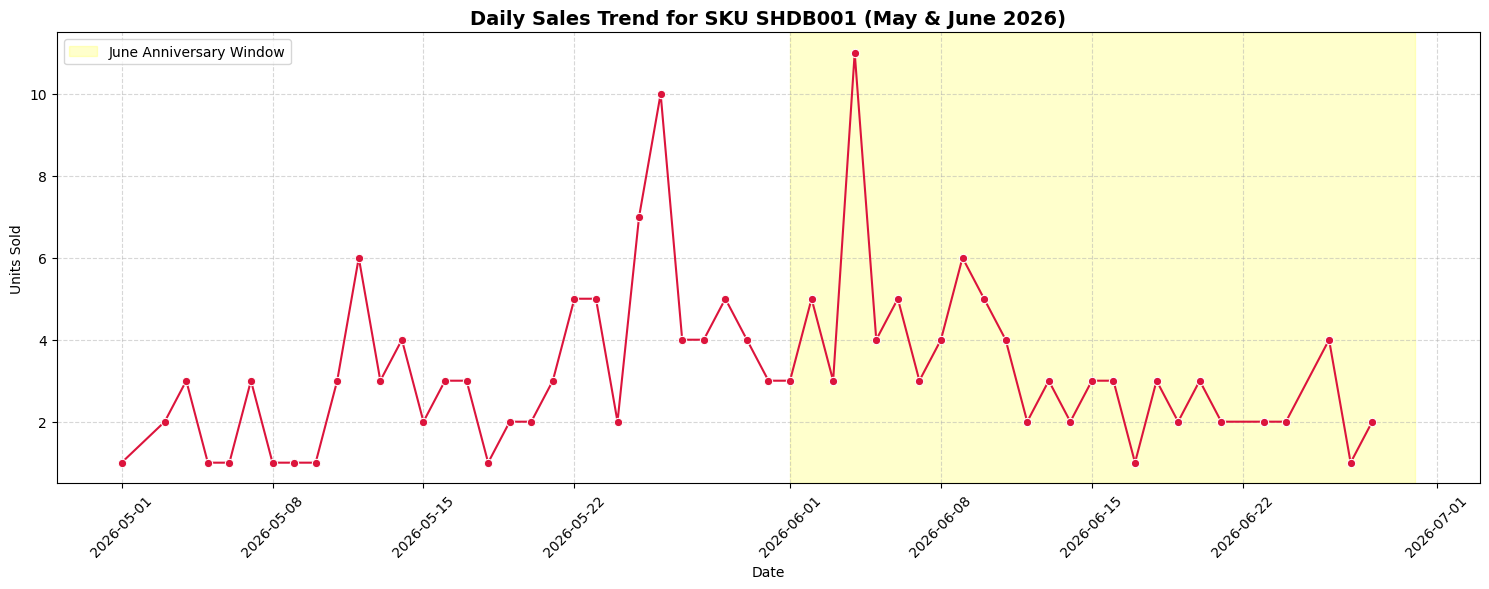

In [ ]:
# Filter sales for May and June 2026
peak_sales = shdb_sales[(shdb_sales['Created At'] >= '2026-05-01') & (shdb_sales['Created At'] <= '2026-06-30')]

# Group by day
daily_peak_sales = peak_sales.groupby(peak_sales['Created At'].dt.date).size().reset_index(name='Daily Sales')

# Plot daily sales over May and June
plt.figure(figsize=(15, 6))
sns.lineplot(data=daily_peak_sales, x='Created At', y='Daily Sales', marker='o', color='crimson')
plt.axvspan(pd.to_datetime('2026-06-01'), pd.to_datetime('2026-06-30'), color='yellow', alpha=0.2, label='June Anniversary Window')
plt.title('Daily Sales Trend for SKU SHDB001 (May & June 2026)', fontsize=14, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Units Sold')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
delivered

,Seller Sku,Jumia Sku,Product SID,Created At,Updated At,Shipped Date,Order Number,Customer First Name,Customer Last Name,National Registration Number,...,Shipment Provider,Shipment Type,Shipping Provider Type,Tracking Code,Tracking URL,Package Gross Weight,Package Volumetric Weight,Premium,Status,Cancel Reason
0,SHDB001,SI162HA34V031NAFAMZ-228682088,942b52f9-6811-4b24-8d52-84e0a3bff7b2,2026-01-02 13:23:21,2026-01-08 12:38:54,2026-01-02 14:14:30,387125857,willis,malesi,NaN,...,NaN,Fulfillment by Jumia,NaN,JG-MCC-373288365-7000,https://packagetracker-services.jumia.com/#/KE...,NaN,NaN,No,Delivered,NaN
1,SHDB001,SI162HA34V031NAFAMZ-228682088,942b52f9-6811-4b24-8d52-84e0a3bff7b2,2026-01-02 17:37:03,2026-01-07 16:24:58,2026-01-02 17:54:31,398355857,Andrew,Peter,NaN,...,NaN,Fulfillment by Jumia,NaN,JE-FDQ-398355857-3751,https://packagetracker-services.jumia.com/#/KE...,NaN,NaN,No,Delivered,NaN
2,SHDB001,SI162HA34V031NAFAMZ-228682088,942b52f9-6811-4b24-8d52-84e0a3bff7b2,2026-01-03 09:53:18,2026-01-06 16:37:16,2026-01-03 12:24:48,313411857,Luke,Kirongo,NaN,...,NaN,Fulfillment by Jumia,NaN,JE-FHP-313411857-1617,https://packagetracker-services.jumia.com/#/KE...,NaN,NaN,No,Delivered,NaN
3,SHDB001,SI162HA34V031NAFAMZ-228682088,942b52f9-6811-4b24-8d52-84e0a3bff7b2,2026-01-04 07:50:33,2026-01-06 17:41:13,2026-01-04 14:40:37,312884757,Kabucho,Karanja,NaN,...,NaN,Fulfillment by Jumia,NaN,JG-GAF-321171365-4279,https://packagetracker-services.jumia.com/#/KE...,NaN,NaN,No,Delivered,NaN
4,SHDB001,SI162HA34V031NAFAMZ-228682088,942b52f9-6811-4b24-8d52-84e0a3bff7b2,2026-01-06 19:31:21,2026-01-09 18:50:34,2026-01-07 11:38:23,357337757,augustine,nyakiba,NaN,...,NaN,Fulfillment by Jumia,NaN,NaN,https://packagetracker-services.jumia.com/#/KE...,NaN,NaN,No,Delivered,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1112,DST001,GE840EA659E3UNAFAMZ-461365251,b530b216-739e-496e-b6e3-d5a844266721,2026-11-09 08:45:26,2026-11-10 12:56:22,2026-11-09 12:51:16,391264555,Suleiman,Asman,NaN,...,NaN,Fulfillment by Jumia,NaN,JE-IAB-391264555-6879,https://packagetracker-services.jumia.com/#/KE...,NaN,NaN,No,Delivered,NaN
1113,SHDB001,SI162HA34V031NAFAMZ-228682088,942b52f9-6811-4b24-8d52-84e0a3bff7b2,2026-11-09 10:44:19,2026-11-10 13:25:55,2026-11-09 12:53:45,325574555,Nancy,Abuga,NaN,...,NaN,Fulfillment by Jumia,NaN,JE-ADF-325574555-2567,https://packagetracker-services.jumia.com/#/KE...,NaN,NaN,No,Delivered,NaN
1114,SHDB001,SI162HA34V031NAFAMZ-228682088,942b52f9-6811-4b24-8d52-84e0a3bff7b2,2026-11-09 20:45:28,2026-11-11 12:43:13,2026-11-10 02:12:45,322436555,Freddy,Lumbs,NaN,...,NaN,Fulfillment by Jumia,NaN,JE-ADF-322436555-5250,https://packagetracker-services.jumia.com/#/KE...,NaN,NaN,No,Delivered,NaN
1115,DST001,GE840EA659E3UNAFAMZ-461365251,b530b216-739e-496e-b6e3-d5a844266721,2026-11-09 22:10:21,2026-11-11 16:45:48,2026-11-10 00:31:47,349729555,Simon,Jura,NaN,...,NaN,Fulfillment by Jumia,NaN,JE-ACB-349729555-7005,https://packagetracker-services.jumia.com/#/KE...,NaN,NaN,No,Delivered,NaN


In [ ]:
# Let's check all the available columns in the delivered dataframe and inspect a few raw rows
print("Available Columns in 'delivered':", delivered.columns.tolist())
display(delivered[['Seller Sku', 'Unit Price', 'Paid Price', 'Shipping Fee', 'Status','Order Number','Updated At','Created At']].tail(10))

Available Columns in 'delivered': ['Seller Sku', 'Jumia Sku', 'Product SID', 'Created At', 'Updated At', 'Shipped Date', 'Order Number', 'Customer First Name', 'Customer Last Name', 'National Registration Number', 'Shipping Address', 'Shipping City', 'Shipping Postal Code', 'Shipping Country', 'Prepayment', 'Paid Price', 'Unit Price', 'Shipping Fee', 'Wallet Credits', 'Item Name', 'Variation', 'Shipment Provider', 'Shipment Type', 'Shipping Provider Type', 'Tracking Code', 'Tracking URL', 'Package Gross Weight', 'Package Volumetric Weight', 'Premium', 'Status', 'Cancel Reason']


,Seller Sku,Unit Price,Paid Price,Shipping Fee,Status,Order Number,Updated At,Created At
1107,SHDB001,2707.50,2707.50,170.0,Delivered,394225755,2026-11-11 10:44:30,2026-11-08 03:30:18
1108,DST001,189.05,189.05,200.0,Delivered,336981755,2026-11-09 15:36:23,2026-11-08 15:20:08
1109,SHDB001,2707.50,2707.50,150.0,Delivered,379781755,2026-11-11 17:58:46,2026-11-08 15:30:10
1110,SHDB001,2707.50,2707.50,245.0,Delivered,334751755,2026-11-11 13:23:08,2026-11-08 16:52:12
1111,DST001,189.05,189.05,106.0,Delivered,391264555,2026-11-10 12:56:22,2026-11-09 08:45:26
1112,DST001,189.05,189.05,106.0,Delivered,391264555,2026-11-10 12:56:22,2026-11-09 08:45:26
1113,SHDB001,2707.50,2707.50,143.0,Delivered,325574555,2026-11-10 13:25:55,2026-11-09 10:44:19
1114,SHDB001,2707.50,2707.50,106.0,Delivered,322436555,2026-11-11 12:43:13,2026-11-09 20:45:28
1115,DST001,189.05,189.05,17.0,Delivered,349729555,2026-11-11 16:45:48,2026-11-09 22:10:21
1116,SHDB001,2707.50,2707.50,475.0,Delivered,316954155,2026-11-11 17:46:20,2026-11-11 14:25:18


In [ ]:
commision_df=pd.read_excel("New-commission-structure-2026.xlsx")
shipping_fee_df=pd.read_excel("2026-New-Shipping-Cost-Contribution-Fees.xlsx")

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Filter for delivered SKU 'SHDB001' that are Express (Fulfillment by Jumia)
# Standard shipment type for express on Jumia is 'Fulfillment by Jumia'
shdb_express = delivered[(delivered['Seller Sku'] == 'SHDB001') & (delivered['Shipment Type'] == 'Fulfillment by Jumia')].copy()

# Clean the Unit Price column
shdb_express['Clean_Price'] = pd.to_numeric(shdb_express['Unit Price'].astype(str).str.replace(' KES', '').str.replace(',', ''), errors='coerce')

# 2. Define financial parameters
cogs_val = 1800.0
# Jumia Commission (12% of selling price)
shdb_express['Commission'] = -0.12 * shdb_express['Clean_Price']
# Jumia Express Shipping Contribution (fixed at 70 KES)
shdb_express['Shipping_Fee'] = -70.0
shdb_express['COGS'] = cogs_val

# 3. Calculate Payout and Profits
shdb_express['Net_Payout'] = shdb_express['Clean_Price'] + shdb_express['Commission'] + shdb_express['Shipping_Fee']
shdb_express['Net_Profit'] = shdb_express['Net_Payout'] - shdb_express['COGS']
shdb_express['Margin_Percentage'] = (shdb_express['Net_Profit'] / shdb_express['Clean_Price']) * 100

# 4. Generate Summary Statistics
total_units_exp = len(shdb_express)
total_revenue_exp = shdb_express['Clean_Price'].sum()
total_cogs_exp = shdb_express['COGS'].sum()
total_commission_exp = shdb_express['Commission'].sum()
total_shipping_exp = shdb_express['Shipping_Fee'].sum()
total_net_profit_exp = shdb_express['Net_Profit'].sum()
avg_margin_exp = shdb_express['Margin_Percentage'].mean()

print(f"=== FINANCIAL PROFITABILITY REPORT (EXPRESS WAREHOUSE) ===")
print(f"Total Express Units Delivered: {total_units_exp}")
print(f"Average Unit Selling Price: {shdb_express['Clean_Price'].mean():.2f} KES")
print(f"Unit COGS: {cogs_val:.2f} KES")
print(f"----------------------------------------------------------")
print(f"Cumulative Revenue: {total_revenue_exp:,.2f} KES")
print(f"Cumulative COGS: {total_cogs_exp:,.2f} KES")
print(f"Cumulative Commission (12%): {total_commission_exp:,.2f} KES")
print(f"Cumulative Shipping Fees (70 KES/unit): {total_shipping_exp:,.2f} KES")
print(f"----------------------------------------------------------")
print(f"Cumulative Net Profit (Express): {total_net_profit_exp:,.2f} KES")
print(f"Average Profit Margin: {avg_margin_exp:.2f}%")

# Display sample transactions
display(shdb_express[['Order Number', 'Created At', 'Clean_Price', 'Commission', 'Shipping_Fee', 'COGS', 'Net_Payout', 'Net_Profit']].tail(10))

=== FINANCIAL PROFITABILITY REPORT (EXPRESS WAREHOUSE) ===
Total Express Units Delivered: 571
Average Unit Selling Price: 3023.28 KES
Unit COGS: 1800.00 KES
----------------------------------------------------------
Cumulative Revenue: 1,726,292.25 KES
Cumulative COGS: 1,027,800.00 KES
Cumulative Commission (12%): -207,155.07 KES
Cumulative Shipping Fees (70 KES/unit): -39,970.00 KES
----------------------------------------------------------
Cumulative Net Profit (Express): 451,367.18 KES
Average Profit Margin: 25.60%


,Order Number,Created At,Clean_Price,Commission,Shipping_Fee,COGS,Net_Payout,Net_Profit
1102,372949755,2026-11-07 01:24:17,2707.5,-324.9,-70.0,1800.0,2312.6,512.6
1103,354438755,2026-11-07 16:10:21,2707.5,-324.9,-70.0,1800.0,2312.6,512.6
1105,387887755,2026-11-07 20:07:09,2707.5,-324.9,-70.0,1800.0,2312.6,512.6
1106,397677755,2026-11-07 20:44:10,2707.5,-324.9,-70.0,1800.0,2312.6,512.6
1107,394225755,2026-11-08 03:30:18,2707.5,-324.9,-70.0,1800.0,2312.6,512.6
1109,379781755,2026-11-08 15:30:10,2707.5,-324.9,-70.0,1800.0,2312.6,512.6
1110,334751755,2026-11-08 16:52:12,2707.5,-324.9,-70.0,1800.0,2312.6,512.6
1113,325574555,2026-11-09 10:44:19,2707.5,-324.9,-70.0,1800.0,2312.6,512.6
1114,322436555,2026-11-09 20:45:28,2707.5,-324.9,-70.0,1800.0,2312.6,512.6
1116,316954155,2026-11-11 14:25:18,2707.5,-324.9,-70.0,1800.0,2312.6,512.6


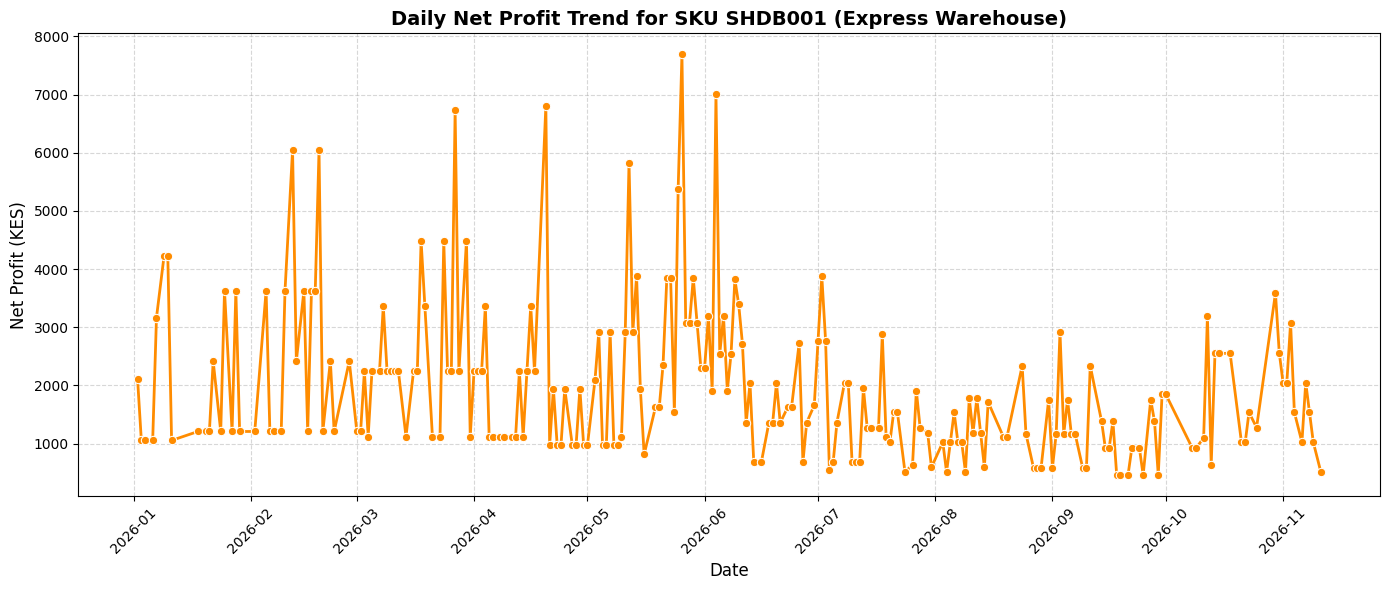

In [ ]:
# 5. Visualize the Net Profit Trend over time for Express Sales
shdb_express['Created At'] = pd.to_datetime(shdb_express['Created At'])
daily_express_profit = shdb_express.groupby(shdb_express['Created At'].dt.date)['Net_Profit'].sum().reset_index()

plt.figure(figsize=(14, 6))
sns.lineplot(data=daily_express_profit, x='Created At', y='Net_Profit', color='darkorange', linewidth=2, marker='o')
plt.title('Daily Net Profit Trend for SKU SHDB001 (Express Warehouse)', fontsize=14, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Net Profit (KES)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()